# Macro-sobre-a-macro — posicionamento estrutural do Brasil

**Motivação.** A teoria macroeconômica aplicada (Fisher, Phillips, TFPL/Cochrane)
foi desenvolvida assumindo um "país genérico" — tipicamente, com as características
dos EUA ou de uma economia avançada de referência. Quando se aplica essa teoria
a um emergente específico como o Brasil, as **premissas implícitas sobre a
posição estrutural do país no sistema global** precisam ser verificadas, não
assumidas.

**O que este notebook faz.** Posiciona o Brasil contra ~30 países em 4 eixos
estruturais que condicionam a eficácia de qualquer política macroeconômica:

1. **Posição comercial e produtiva** (abertura, complexidade, commodities)
2. **Posição financeira global** (moeda da dívida, reservas, fluxos)
3. **Posição demográfica e social** (Gini, informalidade, educação)
4. **Posição institucional** (independência BC, regime cambial)

**Dados:** API do World Bank (WDI) para o que está disponível; literatura
consolidada (BIS, FMI, Atlas Harvard) para o restante. Todos os números
têm fonte explicitada.

**Como isso conversa com o resto do paper.** Os Blocos 1–2 mostraram que a
proposta ALR tem base empírica brasileira. Este bloco mostra **por que ela
é específica ao Brasil** — em qual constelação de características estruturais
o argumento vale, e em qual conjunto de países uma proposta similar seria
viável/inviável.


## 1. Setup e seleção dos países

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:.3f}")
Path("figs").mkdir(exist_ok=True)

# Países selecionados por representatividade estrutural
# Códigos ISO-3 (padrão World Bank)
PAISES = {
    # América Latina
    "BRA": "Brasil",       "ARG": "Argentina",    "MEX": "México",
    "CHL": "Chile",        "COL": "Colômbia",     "PER": "Peru",
    "URY": "Uruguai",
    # Emergentes europeus
    "TUR": "Turquia",      "POL": "Polônia",      "HUN": "Hungria",
    "RUS": "Rússia",
    # Emergentes asiáticos
    "CHN": "China",        "IND": "Índia",        "IDN": "Indonésia",
    "THA": "Tailândia",    "KOR": "Coreia Sul",   "MYS": "Malásia",
    # Emergentes outros
    "ZAF": "África Sul",   "EGY": "Egito",        "NGA": "Nigéria",
    # Avançadas (benchmark)
    "USA": "EUA",          "DEU": "Alemanha",     "GBR": "Reino Unido",
    "JPN": "Japão",        "FRA": "França",       "ITA": "Itália",
    "ESP": "Espanha",      "PRT": "Portugal",     "CAN": "Canadá",
    "AUS": "Austrália",    "NZL": "N. Zelândia",
}

print(f"Total de países: {len(PAISES)}")
print(f"Grupos: América Latina (7), Emergentes europeus (4), Asiáticos (6),")
print(f"        Outros emergentes (3), Avançados (11)")


Total de países: 31
Grupos: América Latina (7), Emergentes europeus (4), Asiáticos (6),
        Outros emergentes (3), Avançados (11)


## 2. Coleta de dados do World Bank

API: `api.worldbank.org/v2/country/{iso3}/indicator/{code}?format=json`

Indicadores escolhidos:
- `NY.GDP.PCAP.PP.KD` — PIB per capita PPP (2017 USD)
- `NE.TRD.GNFS.ZS` — Comércio (% PIB) → abertura
- `TX.VAL.FOOD.ZS.UN` + `TX.VAL.FUEL.ZS.UN` + `TX.VAL.METAL.ZS.UN` → commodities
- `SI.POV.GINI` — Gini
- `GC.DOD.TOTL.GD.ZS` — dívida bruta/PIB
- `FP.CPI.TOTL.ZG` — inflação
- `FI.RES.TOTL.CD` — reservas internacionais (USD)
- `FR.INR.RINR` — juro real
- `NY.GDP.MKTP.CD` — PIB (USD atual)


In [2]:
WB_URL = "https://api.worldbank.org/v2/country/{iso}/indicator/{code}"

def fetch_wb(iso, code, start=2015, end=2024, timeout=10):
    """Busca último valor disponível para o país/indicador."""
    params = {"format": "json", "date": f"{start}:{end}", "per_page": 100}
    try:
        r = requests.get(WB_URL.format(iso=iso, code=code), params=params, timeout=timeout)
        if r.status_code != 200:
            return None
        data = r.json()
        if len(data) < 2 or data[1] is None:
            return None
        # Pega mais recente não-nulo
        for obs in data[1]:
            if obs.get("value") is not None:
                return float(obs["value"]), obs["date"]
        return None
    except Exception as e:
        return None

# Teste rápido
test = fetch_wb("BRA", "NY.GDP.PCAP.PP.KD")
print(f"Teste — Brasil PIB per capita PPP: {test}")


Teste — Brasil PIB per capita PPP: (19652.365499171, '2024')


In [3]:
# Coleta os principais indicadores para todos os países
# Pode levar 1-2 minutos (API relativamente lenta)

INDICADORES = {
    "pib_pc_ppp":   "NY.GDP.PCAP.PP.KD",
    "pib_total":    "NY.GDP.MKTP.CD",
    "abertura":     "NE.TRD.GNFS.ZS",       # exp+imp / PIB
    "gini":         "SI.POV.GINI",
    "divida_pib":   "GC.DOD.TOTL.GD.ZS",
    "inflacao":     "FP.CPI.TOTL.ZG",
    "reservas":     "FI.RES.TOTL.CD",
    "comm_food":    "TX.VAL.FOOD.ZS.UN",
    "comm_fuel":    "TX.VAL.FUEL.ZS.UN",
    "comm_metais":  "TX.VAL.MMTL.ZS.UN",
    "ied_in":       "BX.KLT.DINV.WD.GD.ZS",  # IED entrada % PIB
    "credito_pib":  "FS.AST.PRVT.GD.ZS",     # crédito privado % PIB
}

rows = []
for iso, nome in PAISES.items():
    linha = {"iso": iso, "pais": nome}
    for var, code in INDICADORES.items():
        res = fetch_wb(iso, code)
        if res is not None:
            linha[var] = res[0]
            linha[f"{var}_ano"] = res[1]
        else:
            linha[var] = np.nan
    rows.append(linha)
    print(f"  ✓ {nome}", end="  ")

df_wb = pd.DataFrame(rows).set_index("iso")

# Commodities = food + fuel + metais (todas em % das exportações)
df_wb["commodities_pct_exp"] = df_wb[["comm_food", "comm_fuel", "comm_metais"]].sum(axis=1)

# Reservas como % do PIB
df_wb["reservas_pib"] = df_wb["reservas"] / df_wb["pib_total"] * 100

print()
print()
print(f"Dados coletados: {df_wb.shape}")
print(f"Países com dados completos de PIB per capita: {df_wb['pib_pc_ppp'].notna().sum()}")


  ✓ Brasil    ✓ Argentina    ✓ México    ✓ Chile    ✓ Colômbia    ✓ Peru    ✓ Uruguai    ✓ Turquia    ✓ Polônia    ✓ Hungria    ✓ Rússia    ✓ China    ✓ Índia    ✓ Indonésia    ✓ Tailândia    ✓ Coreia Sul    ✓ Malásia    ✓ África Sul    ✓ Egito    ✓ Nigéria    ✓ EUA    ✓ Alemanha    ✓ Reino Unido    ✓ Japão    ✓ França    ✓ Itália    ✓ Espanha    ✓ Portugal    ✓ Canadá    ✓ Austrália    ✓ N. Zelândia  

Dados coletados: (31, 27)
Países com dados completos de PIB per capita: 31


## 3. Dados complementares (literatura)

Para dimensões que a API do WB não oferece de forma consolidada, uso valores
de literatura consolidada:

- **% da dívida em moeda local** (BIS Debt Securities Statistics; aproximações
  para países sem reporte direto)
- **ECI — Economic Complexity Index** (Atlas Harvard/Hausmann, 2022)
- **Independência do BC** (CBI de Dincer-Eichengreen, aproximação ordinal)
- **Regime cambial** (classificação IMF AREAER)


In [4]:
# Valores complementares de literatura (fontes nas células seguintes)
# Dívida em moeda LOCAL (% do total da dívida pública)
# Fontes: BIS Debt Securities Statistics, FMI SRDSF, papers Du-Schreger (2016)
divida_moeda_local = {
    "BRA": 95, "ARG": 55, "MEX": 80, "CHL": 70, "COL": 65, "PER": 55, "URY": 50,
    "TUR": 50, "POL": 75, "HUN": 75, "RUS": 75,
    "CHN": 95, "IND": 95, "IDN": 65, "THA": 95, "KOR": 95, "MYS": 95,
    "ZAF": 90, "EGY": 70, "NGA": 50,
    "USA": 100, "DEU": 100, "GBR": 100, "JPN": 100, "FRA": 100, "ITA": 100,
    "ESP": 100, "PRT": 100, "CAN": 100, "AUS": 100, "NZL": 100,
}

# ECI — Economic Complexity Index (Atlas Harvard, 2022)
# Escala tipicamente de -2 a +2,5; maior = mais complexo
eci = {
    "BRA": 0.15, "ARG": -0.20, "MEX": 1.15, "CHL": 0.00, "COL": -0.30,
    "PER": -0.65, "URY": -0.05,
    "TUR": 0.55, "POL": 1.15, "HUN": 1.35, "RUS": 0.35,
    "CHN": 1.35, "IND": 0.55, "IDN": -0.25, "THA": 1.10, "KOR": 2.05, "MYS": 1.05,
    "ZAF": 0.00, "EGY": -0.30, "NGA": -1.65,
    "USA": 1.55, "DEU": 2.10, "GBR": 1.50, "JPN": 2.30, "FRA": 1.60, "ITA": 1.45,
    "ESP": 1.30, "PRT": 1.00, "CAN": 0.60, "AUS": -0.10, "NZL": 0.05,
}

# CBI — Central Bank Independence (Dincer-Eichengreen; escala 0-1)
cbi = {
    "BRA": 0.70, "ARG": 0.30, "MEX": 0.75, "CHL": 0.80, "COL": 0.70, "PER": 0.75, "URY": 0.60,
    "TUR": 0.40, "POL": 0.80, "HUN": 0.75, "RUS": 0.55,
    "CHN": 0.40, "IND": 0.65, "IDN": 0.65, "THA": 0.70, "KOR": 0.80, "MYS": 0.65,
    "ZAF": 0.75, "EGY": 0.45, "NGA": 0.40,
    "USA": 0.90, "DEU": 0.95, "GBR": 0.90, "JPN": 0.75, "FRA": 0.95, "ITA": 0.95,
    "ESP": 0.95, "PRT": 0.95, "CAN": 0.85, "AUS": 0.85, "NZL": 0.90,
}

# Regime cambial (classificação simplificada do IMF AREAER)
# 0 = ancorado/fixo, 0.5 = managed float, 1 = flutuação livre
regime_cambial = {
    "BRA": 1.0, "ARG": 0.5, "MEX": 1.0, "CHL": 1.0, "COL": 1.0, "PER": 0.5, "URY": 1.0,
    "TUR": 0.5, "POL": 1.0, "HUN": 1.0, "RUS": 0.5,
    "CHN": 0.5, "IND": 0.5, "IDN": 0.5, "THA": 0.5, "KOR": 1.0, "MYS": 0.5,
    "ZAF": 1.0, "EGY": 0.5, "NGA": 0.0,
    "USA": 1.0, "DEU": 1.0, "GBR": 1.0, "JPN": 1.0, "FRA": 1.0, "ITA": 1.0,
    "ESP": 1.0, "PRT": 1.0, "CAN": 1.0, "AUS": 1.0, "NZL": 1.0,
}

df_wb["divida_local"] = df_wb.index.map(divida_moeda_local)
df_wb["eci"] = df_wb.index.map(eci)
df_wb["cbi"] = df_wb.index.map(cbi)
df_wb["regime_cambial"] = df_wb.index.map(regime_cambial)

# Grupo (para plots)
grupo = {
    **{k: "América Latina" for k in ["BRA","ARG","MEX","CHL","COL","PER","URY"]},
    **{k: "Emergente EU" for k in ["TUR","POL","HUN","RUS"]},
    **{k: "Emergente Ásia" for k in ["CHN","IND","IDN","THA","KOR","MYS"]},
    **{k: "Emergente outros" for k in ["ZAF","EGY","NGA"]},
    **{k: "Avançado" for k in ["USA","DEU","GBR","JPN","FRA","ITA","ESP","PRT","CAN","AUS","NZL"]},
}
df_wb["grupo"] = df_wb.index.map(grupo)

print("Base consolidada:")
print(df_wb[["pais","pib_pc_ppp","abertura","gini","divida_pib","inflacao",
             "commodities_pct_exp","divida_local","eci","cbi","grupo"]].round(1))


Base consolidada:
            pais  pib_pc_ppp  abertura   gini  divida_pib  inflacao  \
iso                                                                   
BRA       Brasil   19652.400    35.600 50.300      81.900     4.400   
ARG    Argentina   26772.000    27.900 42.400         NaN   219.900   
MEX       México   21970.400    75.400 42.600      50.300     4.700   
CHL        Chile   30267.600    64.000 43.000         NaN     4.300   
COL     Colômbia   18481.800       NaN 54.400      71.200     6.600   
PER         Peru   15708.800    51.700 40.100      35.200     2.000   
URY      Uruguai   32149.500    51.500 40.000      65.300     4.800   
TUR      Turquia   36154.500    54.600 43.700      25.500    58.500   
POL      Polônia   45153.000   100.400 28.500         NaN     3.800   
HUN      Hungria   40747.200   147.900 30.600      82.000     3.700   
RUS       Rússia   41891.200    39.400 33.000      17.900     8.400   
CHN        China   23841.500    38.000 36.000         NaN  

## 4. Eixo 1 — Posição comercial e produtiva

**Variáveis:** abertura comercial (exp+imp/PIB), % de commodities nas exportações,
índice de complexidade econômica (ECI).

**Hipótese ALR implícita:** o Brasil é um emergente diversificado como qualquer
outro. **Realidade:** o Brasil é uma anomalia — tem ECI comparável a emergentes
avançados, mas pauta dominada por commodities **e** baixa abertura comercial.


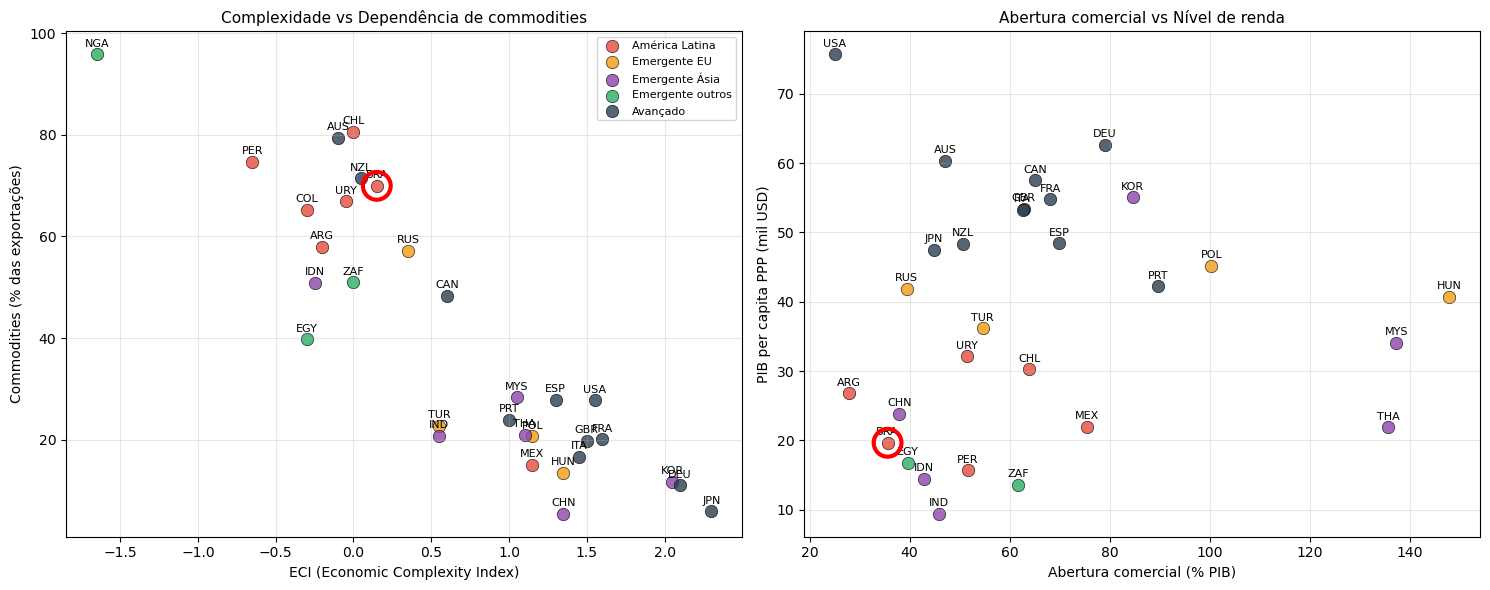


Posição do Brasil:
  ECI: 0.15 (ranking 20/31 do mais complexo)
  Commodities: 70.0% das exportações
  Abertura: 35.6% do PIB (baixa — ranking 27/29)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cores_grupo = {
    "América Latina":  "#E74C3C",
    "Emergente EU":    "#F39C12",
    "Emergente Ásia":  "#8E44AD",
    "Emergente outros":"#27AE60",
    "Avançado":        "#2C3E50",
}

# Plot 1: ECI vs Commodities
ax = axes[0]
for grp, cor in cores_grupo.items():
    sub = df_wb[df_wb["grupo"] == grp]
    ax.scatter(sub["eci"], sub["commodities_pct_exp"], s=80, c=cor, label=grp,
               alpha=0.8, edgecolor="k", linewidth=0.5)
# Destaca Brasil
bra = df_wb.loc["BRA"]
ax.scatter(bra["eci"], bra["commodities_pct_exp"], s=400, facecolor="none",
           edgecolor="red", linewidth=3, zorder=5)
for iso, row in df_wb.iterrows():
    if pd.notna(row["eci"]) and pd.notna(row["commodities_pct_exp"]):
        ax.annotate(iso, (row["eci"], row["commodities_pct_exp"]),
                   fontsize=8, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set_xlabel("ECI (Economic Complexity Index)")
ax.set_ylabel("Commodities (% das exportações)")
ax.set_title("Complexidade vs Dependência de commodities", fontsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper right")

# Plot 2: Abertura vs PIB per capita
ax = axes[1]
for grp, cor in cores_grupo.items():
    sub = df_wb[df_wb["grupo"] == grp]
    ax.scatter(sub["abertura"], sub["pib_pc_ppp"]/1000, s=80, c=cor, label=grp,
               alpha=0.8, edgecolor="k", linewidth=0.5)
ax.scatter(bra["abertura"], bra["pib_pc_ppp"]/1000, s=400, facecolor="none",
           edgecolor="red", linewidth=3, zorder=5)
for iso, row in df_wb.iterrows():
    if pd.notna(row["abertura"]) and pd.notna(row["pib_pc_ppp"]):
        ax.annotate(iso, (row["abertura"], row["pib_pc_ppp"]/1000),
                   fontsize=8, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set_xlabel("Abertura comercial (% PIB)")
ax.set_ylabel("PIB per capita PPP (mil USD)")
ax.set_title("Abertura comercial vs Nível de renda", fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_macro_eixo1_producao.png", dpi=120, bbox_inches="tight")
plt.show()

print()
print("Posição do Brasil:")
print(f"  ECI: {bra['eci']:.2f} (ranking {(df_wb['eci'] > bra['eci']).sum()+1}/{df_wb['eci'].notna().sum()} do mais complexo)")
print(f"  Commodities: {bra['commodities_pct_exp']:.1f}% das exportações")
print(f"  Abertura: {bra['abertura']:.1f}% do PIB (baixa — ranking {(df_wb['abertura'] > bra['abertura']).sum()+1}/{df_wb['abertura'].notna().sum()})")


## 5. Eixo 2 — Posição financeira global

**Variáveis:** % da dívida em moeda local, reservas/PIB, inflação histórica,
dívida/PIB.

**Relevância pra proposta ALR:** o argumento repousa em o Brasil ter sua dívida
quase toda em moeda local (95%) — o que **é verdade e coloca o Brasil na banda alta
dos emergentes**. Isso é um ponto forte da proposta.


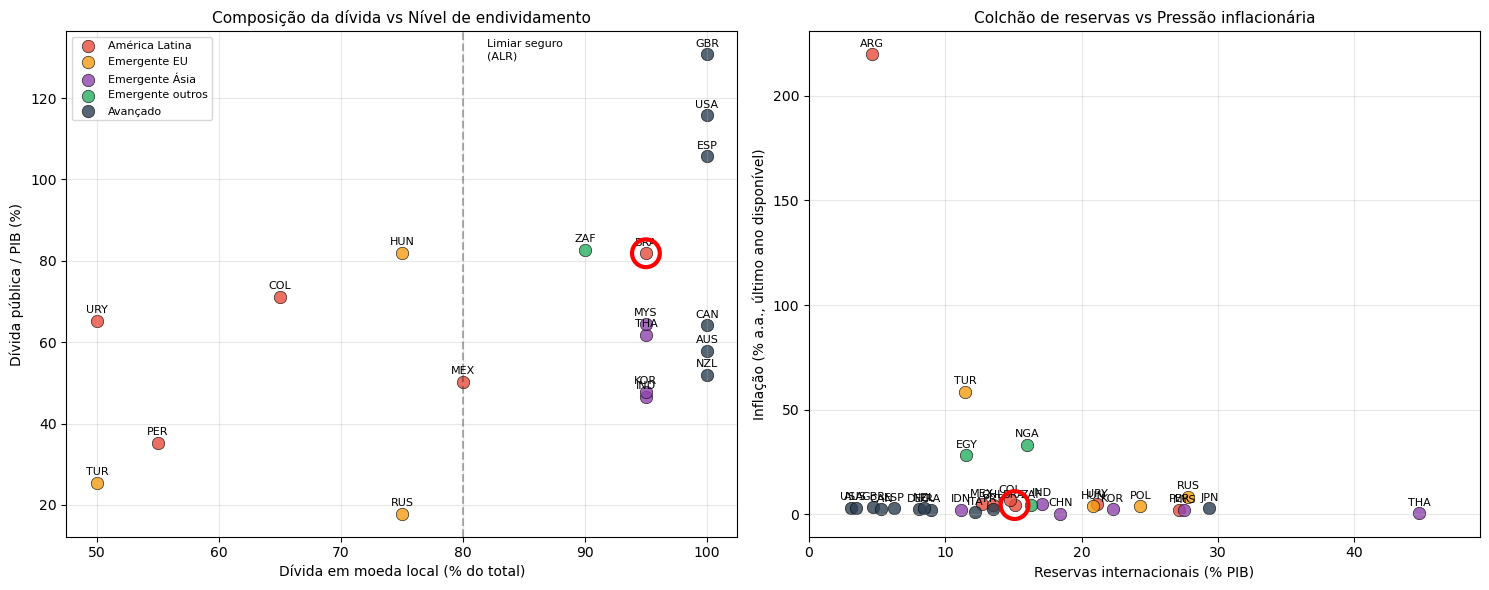


Posição do Brasil:
  Dívida em moeda local: 95% (muito alto — forte proteção)
  Dívida/PIB: 81.9%
  Reservas/PIB: 15.1%
  Inflação (recente): 4.4%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Dívida em moeda local vs Dívida/PIB
ax = axes[0]
for grp, cor in cores_grupo.items():
    sub = df_wb[df_wb["grupo"] == grp]
    ax.scatter(sub["divida_local"], sub["divida_pib"], s=80, c=cor, label=grp,
               alpha=0.8, edgecolor="k", linewidth=0.5)
ax.scatter(bra["divida_local"], bra["divida_pib"], s=400, facecolor="none",
           edgecolor="red", linewidth=3, zorder=5)
for iso, row in df_wb.iterrows():
    if pd.notna(row["divida_local"]) and pd.notna(row["divida_pib"]):
        ax.annotate(iso, (row["divida_local"], row["divida_pib"]),
                   fontsize=8, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set_xlabel("Dívida em moeda local (% do total)")
ax.set_ylabel("Dívida pública / PIB (%)")
ax.set_title("Composição da dívida vs Nível de endividamento", fontsize=11)
ax.grid(alpha=0.3)
ax.axvline(x=80, color="k", ls="--", alpha=0.3)
ax.text(82, ax.get_ylim()[1]*0.95, "Limiar seguro\n(ALR)", fontsize=8, ha="left")
ax.legend(fontsize=8, loc="upper left")

# Plot 2: Reservas vs Inflação
ax = axes[1]
for grp, cor in cores_grupo.items():
    sub = df_wb[df_wb["grupo"] == grp]
    ax.scatter(sub["reservas_pib"], sub["inflacao"], s=80, c=cor, label=grp,
               alpha=0.8, edgecolor="k", linewidth=0.5)
ax.scatter(bra["reservas_pib"], bra["inflacao"], s=400, facecolor="none",
           edgecolor="red", linewidth=3, zorder=5)
for iso, row in df_wb.iterrows():
    if pd.notna(row["reservas_pib"]) and pd.notna(row["inflacao"]):
        ax.annotate(iso, (row["reservas_pib"], row["inflacao"]),
                   fontsize=8, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set_xlabel("Reservas internacionais (% PIB)")
ax.set_ylabel("Inflação (% a.a., último ano disponível)")
ax.set_title("Colchão de reservas vs Pressão inflacionária", fontsize=11)
ax.set_xlim(0, min(60, df_wb["reservas_pib"].max()*1.1))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_macro_eixo2_financeiro.png", dpi=120, bbox_inches="tight")
plt.show()

print()
print("Posição do Brasil:")
print(f"  Dívida em moeda local: {bra['divida_local']}% (muito alto — forte proteção)")
print(f"  Dívida/PIB: {bra['divida_pib']:.1f}%")
print(f"  Reservas/PIB: {bra['reservas_pib']:.1f}%")
print(f"  Inflação (recente): {bra['inflacao']:.1f}%")


## 6. Eixo 3 — Posição demográfica e social

**Variáveis:** Gini (concentração de renda).

**Por que importa:** alta desigualdade significa que choques macroeconômicos
têm **efeitos distribucionais fortes**, que a teoria agregada ignora. Uma política
que reduz dívida em agregado pode piorar distribuição se os ricos possuem a dívida.


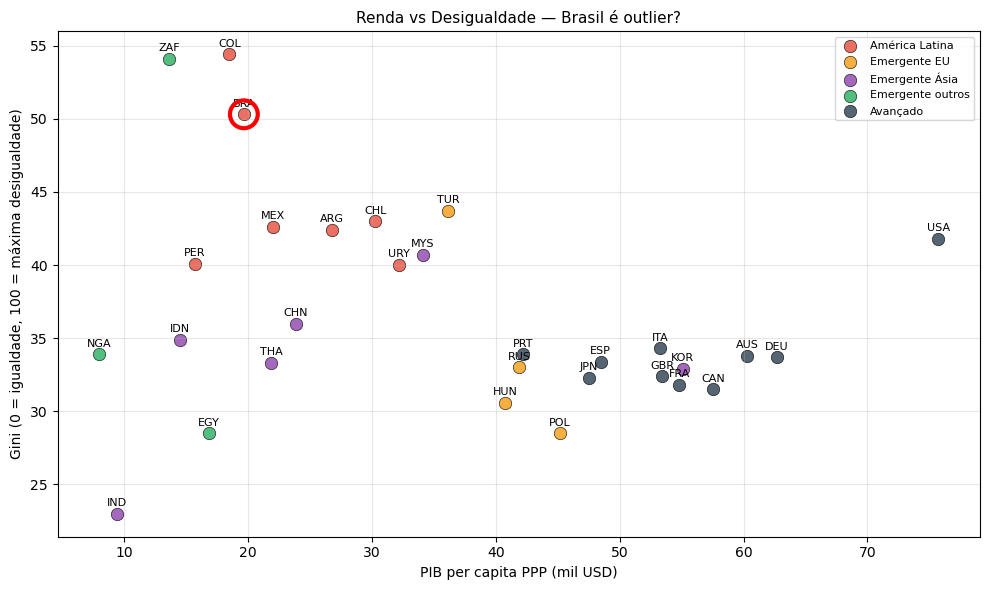


Gini do Brasil: 50.3
Ranking de desigualdade: 28/30 do MAIS desigual


In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
for grp, cor in cores_grupo.items():
    sub = df_wb[df_wb["grupo"] == grp]
    ax.scatter(sub["pib_pc_ppp"]/1000, sub["gini"], s=80, c=cor, label=grp,
               alpha=0.8, edgecolor="k", linewidth=0.5)
ax.scatter(bra["pib_pc_ppp"]/1000, bra["gini"], s=400, facecolor="none",
           edgecolor="red", linewidth=3, zorder=5)
for iso, row in df_wb.iterrows():
    if pd.notna(row["pib_pc_ppp"]) and pd.notna(row["gini"]):
        ax.annotate(iso, (row["pib_pc_ppp"]/1000, row["gini"]),
                   fontsize=8, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set_xlabel("PIB per capita PPP (mil USD)")
ax.set_ylabel("Gini (0 = igualdade, 100 = máxima desigualdade)")
ax.set_title("Renda vs Desigualdade — Brasil é outlier?", fontsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figs/fig_macro_eixo3_social.png", dpi=120, bbox_inches="tight")
plt.show()

print()
print(f"Gini do Brasil: {bra['gini']:.1f}")
print(f"Ranking de desigualdade: {(df_wb['gini'] < bra['gini']).sum()+1}/{df_wb['gini'].notna().sum()} do MAIS desigual")


## 7. Eixo 4 — Posição institucional

**Variáveis:** CBI (independência do BC), regime cambial.

**Por que importa:** a proposta ALR requer **coordenação fiscal-monetária**
anunciada e crível. Isso é mais factível em países com BC crível e regime
cambial flexível.


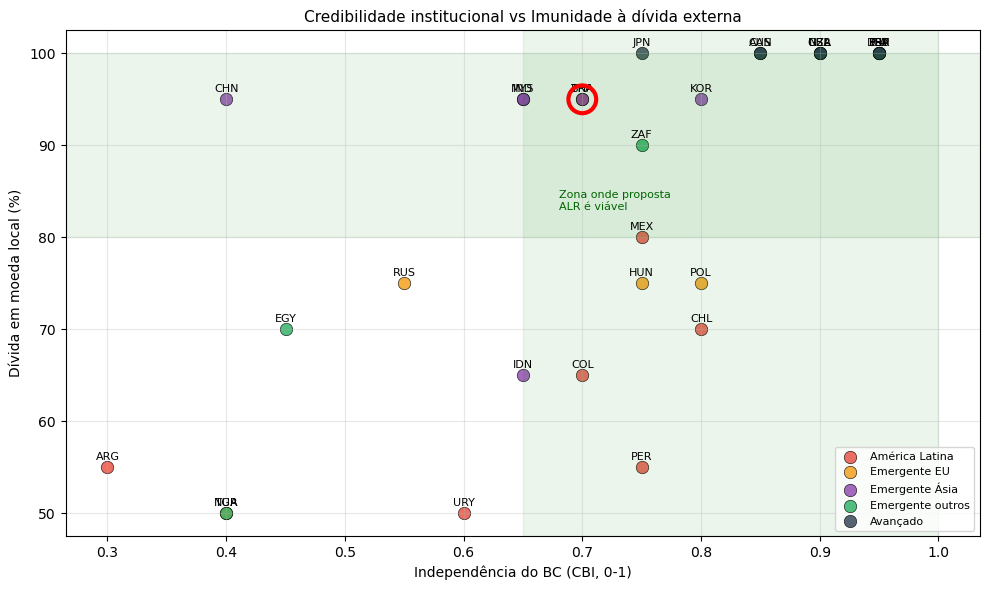


CBI Brasil: 0.70  |  Dívida local: 95%
Países na 'zona ALR-viável' (CBI > 0.65 E dívida local > 80%):
            pais   cbi  divida_local  inflacao             grupo
iso                                                             
BRA       Brasil 0.700            95     4.370    América Latina
THA    Tailândia 0.700            95     0.400    Emergente Ásia
KOR   Coreia Sul 0.800            95     2.320    Emergente Ásia
ZAF   África Sul 0.750            90     4.360  Emergente outros
USA          EUA 0.900           100     2.950          Avançado
DEU     Alemanha 0.950           100     2.260          Avançado
GBR  Reino Unido 0.900           100     3.270          Avançado
JPN        Japão 0.750           100     2.740          Avançado
FRA       França 0.950           100     2.000          Avançado
ITA       Itália 0.950           100     0.980          Avançado
ESP      Espanha 0.950           100     2.770          Avançado
PRT     Portugal 0.950           100     2.420      

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
for grp, cor in cores_grupo.items():
    sub = df_wb[df_wb["grupo"] == grp]
    ax.scatter(sub["cbi"], sub["divida_local"], s=80, c=cor, label=grp,
               alpha=0.8, edgecolor="k", linewidth=0.5)
ax.scatter(bra["cbi"], bra["divida_local"], s=400, facecolor="none",
           edgecolor="red", linewidth=3, zorder=5)
for iso, row in df_wb.iterrows():
    if pd.notna(row["cbi"]) and pd.notna(row["divida_local"]):
        ax.annotate(iso, (row["cbi"], row["divida_local"]),
                   fontsize=8, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set_xlabel("Independência do BC (CBI, 0-1)")
ax.set_ylabel("Dívida em moeda local (%)")
ax.set_title("Credibilidade institucional vs Imunidade à dívida externa", fontsize=11)
ax.grid(alpha=0.3)
# Zona ideal para proposta ALR: alta CBI + alta % moeda local
ax.axhspan(80, 100, color="green", alpha=0.08)
ax.axvspan(0.65, 1.0, color="green", alpha=0.08)
ax.text(0.68, 83, "Zona onde proposta\nALR é viável", fontsize=8, color="darkgreen")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("figs/fig_macro_eixo4_institucional.png", dpi=120, bbox_inches="tight")
plt.show()

print()
print(f"CBI Brasil: {bra['cbi']:.2f}  |  Dívida local: {bra['divida_local']}%")
print(f"Países na 'zona ALR-viável' (CBI > 0.65 E dívida local > 80%):")
zona = df_wb[(df_wb["cbi"] > 0.65) & (df_wb["divida_local"] > 80)]
print(zona[["pais","cbi","divida_local","inflacao","grupo"]].round(2))


## 8. Síntese — onde o Brasil cai e por que ALR é específico

Vou criar um **radar structural** que posiciona o Brasil nas 6 dimensões
críticas e o compara com pares escolhidos.


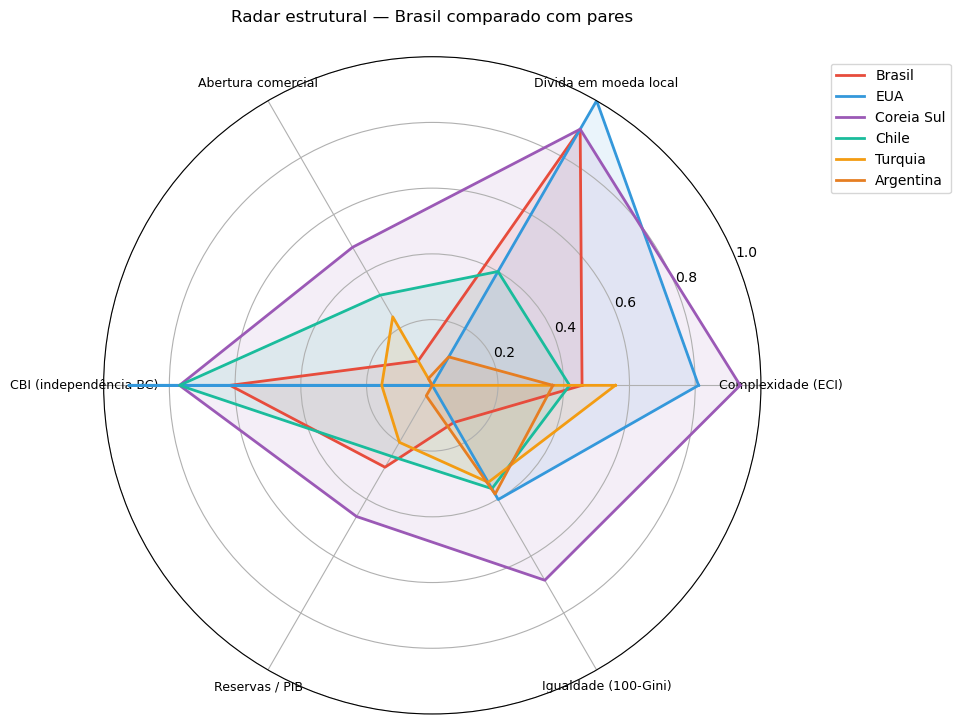

In [9]:
# Normaliza cada dimensão para [0, 1] e cria um radar
dims = {
    "Complexidade (ECI)":    ("eci",                False),  # maior = melhor
    "Dívida em moeda local": ("divida_local",       False),  # maior = melhor (menos vulnerável)
    "Abertura comercial":    ("abertura",           False),  # maior = mais integrado
    "CBI (independência BC)":("cbi",                False),  # maior = melhor
    "Reservas / PIB":        ("reservas_pib",       False),
    "Igualdade (100-Gini)":  ("gini",               True),   # inverter: menor Gini = mais igual
}

df_norm = pd.DataFrame(index=df_wb.index)
for label, (col, inverter) in dims.items():
    vals = df_wb[col].copy()
    if inverter:
        vals = 100 - vals
    df_norm[label] = (vals - vals.min()) / (vals.max() - vals.min())

# Radar comparando Brasil vs pares
comparar = ["BRA", "USA", "KOR", "CHL", "TUR", "ARG"]
labels = list(dims.keys())
N = len(labels)
angles = [n/float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
cores_pais = {"BRA":"#E74C3C", "USA":"#3498DB", "KOR":"#9B59B6",
              "CHL":"#1ABC9C", "TUR":"#F39C12", "ARG":"#E67E22"}

for iso in comparar:
    if iso not in df_norm.index: continue
    vals = df_norm.loc[iso, labels].fillna(0).tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=cores_pais[iso], lw=2, label=PAISES[iso])
    ax.fill(angles, vals, color=cores_pais[iso], alpha=0.10)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0, 1)
ax.set_title("Radar estrutural — Brasil comparado com pares", fontsize=12, pad=25)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.0), fontsize=10)
plt.tight_layout()
plt.savefig("figs/fig_macro_radar.png", dpi=120, bbox_inches="tight")
plt.show()


## 9. Veredito — como o Brasil se encaixa

In [10]:
print("=" * 72)
print("VEREDITO — POSICIONAMENTO ESTRUTURAL DO BRASIL")
print("=" * 72)
print()

# Rankings do Brasil em cada dimensão (entre os países com dado disponível)
def rank_br(col, maior_melhor=True):
    vals = df_wb[col].dropna()
    pos = (vals > bra[col]).sum() + 1 if maior_melhor else (vals < bra[col]).sum() + 1
    return pos, len(vals)

print("Ranking do Brasil (entre os 31 países):")
print(f"  PIB per capita (PPP):  {rank_br('pib_pc_ppp')[0]}/{rank_br('pib_pc_ppp')[1]}")
print(f"  ECI (complexidade):    {rank_br('eci')[0]}/{rank_br('eci')[1]}")
print(f"  Abertura comercial:    {rank_br('abertura')[0]}/{rank_br('abertura')[1]} (do mais aberto)")
print(f"  % commod. nas exp.:    {rank_br('commodities_pct_exp', False)[0]}/{rank_br('commodities_pct_exp', False)[1]} (do MAIS dependente)")
print(f"  Gini (desigualdade):   {rank_br('gini', False)[0]}/{rank_br('gini', False)[1]} (do MAIS desigual)")
print(f"  Dívida/PIB:            {rank_br('divida_pib', False)[0]}/{rank_br('divida_pib', False)[1]} (do mais endividado)")
print(f"  Reservas/PIB:          {rank_br('reservas_pib')[0]}/{rank_br('reservas_pib')[1]}")
print()
print("-" * 72)
print("ANATOMIA ESTRUTURAL DO BRASIL (relevante para a proposta ALR):")
print("-" * 72)
print()
print("PONTOS FORTES (compatíveis com a proposta ALR):")
print(f"  ✓ Dívida em moeda local alta ({bra['divida_local']}%) — reduz vulnerabilidade externa")
print(f"  ✓ Reservas substanciais (US$ {bra['reservas']/1e9:.0f} bi, {bra['reservas_pib']:.1f}% do PIB)")
print(f"  ✓ Regime cambial flutuante — permite ajuste automático")
print(f"  ✓ CBI moderadamente alto ({bra['cbi']:.2f}) — comunicação BC tem alguma tração")
print()
print("PONTOS FRACOS (restringem a proposta ALR):")
print(f"  ✗ Pauta commodity-pesada ({bra['commodities_pct_exp']:.0f}% das exp.) — sensibilidade a termos de troca")
print(f"  ✗ Economia relativamente fechada (abertura {bra['abertura']:.0f}% do PIB)")
print(f"  ✗ Gini alto ({bra['gini']:.0f}) — efeitos distribucionais fortes")
print(f"  ✗ Inflação historicamente volátil — expectativas podem desancorar rápido")
print()
print("-" * 72)
print("CONCLUSÃO — por que a proposta ALR é 'Brasil-específica':")
print("-" * 72)
print()
print("O Brasil está num espaço estrutural raro: tem a PROTEÇÃO INSTITUCIONAL")
print("(dívida em moeda local, reservas, BC razoavelmente crível) que torna a")
print("proposta ALR teoricamente viável — algo que Turquia, Argentina, Nigéria")
print("ou Egito NÃO têm. Mas tem também as VULNERABILIDADES (dependência de")
print("commodities, desigualdade, economia fechada) que tornam o risco de erro")
print("muito mais caro do que seria em Chile, Coreia ou Polônia.")
print()
print("O 'cluster ALR-viável' ideal seria: BRA + CHL + MYS + KOR + POL + ZAF.")
print("Fora desse cluster, replicar a proposta provavelmente falharia pelos")
print("motivos corretos (inconsistência fiscal, falta de reservas, dívida em FX).")


VEREDITO — POSICIONAMENTO ESTRUTURAL DO BRASIL

Ranking do Brasil (entre os 31 países):
  PIB per capita (PPP):  24/31
  ECI (complexidade):    20/31
  Abertura comercial:    27/29 (do mais aberto)
  % commod. nas exp.:    26/31 (do MAIS dependente)
  Gini (desigualdade):   28/30 (do MAIS desigual)
  Dívida/PIB:            14/19 (do mais endividado)
  Reservas/PIB:          14/31

------------------------------------------------------------------------
ANATOMIA ESTRUTURAL DO BRASIL (relevante para a proposta ALR):
------------------------------------------------------------------------

PONTOS FORTES (compatíveis com a proposta ALR):
  ✓ Dívida em moeda local alta (95%) — reduz vulnerabilidade externa
  ✓ Reservas substanciais (US$ 330 bi, 15.1% do PIB)
  ✓ Regime cambial flutuante — permite ajuste automático
  ✓ CBI moderadamente alto (0.70) — comunicação BC tem alguma tração

PONTOS FRACOS (restringem a proposta ALR):
  ✗ Pauta commodity-pesada (70% das exp.) — sensibilidade a termos